# 1 Analiza danych

In [1]:
import pandas as pd

penguins = pd.read_csv("penguins.csv")

print("penguins.head()")
display(penguins.head())  # Wyświetlenie kilku pierwszych rekordów

print("\npenguins.info()")
penguins.info()  # Wyświetlenie dtype danych obiektu DataFrame

print("\npenguins.isna().sum()")
print(penguins.isna().sum())  # Wyświetlenie ilości brakujących rekordów

num_init_rows = penguins.shape[0]
penguins = penguins.dropna()  # Usunięcie brakujących rekordów
removed_pct = (num_init_rows - penguins.shape[0]) / num_init_rows * 100
print(f"\nUsunięte rekordy stanowiły: {round(removed_pct, 2)}%")

print("\npenguins.duplicated().sum()")
print(penguins.duplicated().sum())  # Sprawdzenie czy wszystkie rekordy są unikalne

penguins.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



penguins.info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB

penguins.isna().sum()
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Usunięte rekordy stanowiły: 3.2%

penguins.duplicated().sum()
0


## 1.1 Dane kategoryczne

penguins["species"].unique()
['Adelie' 'Chinstrap' 'Gentoo']

penguins["island"].unique()
['Torgersen' 'Biscoe' 'Dream']

penguins["species"].value_counts()
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

penguins["island"].value_counts()
island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64


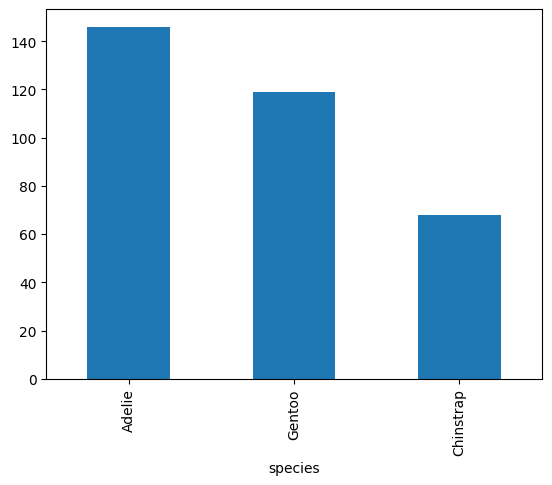

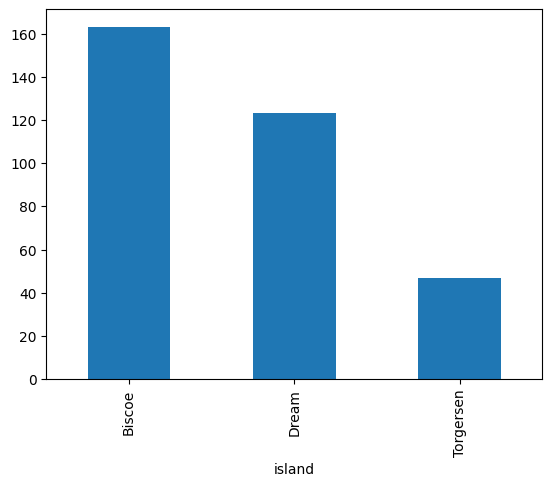

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,119
Dream,55,68,0
Torgersen,47,0,0


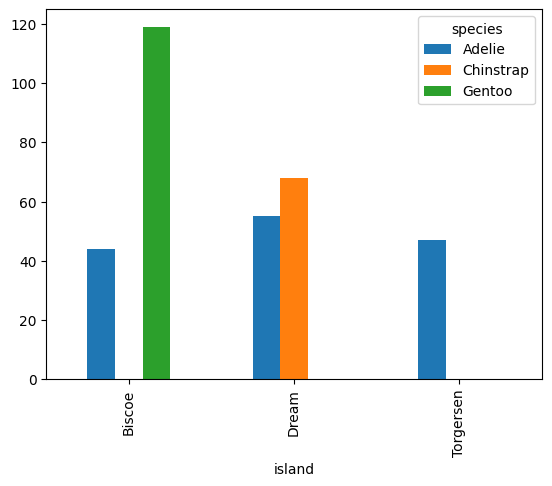

In [2]:
import matplotlib.pyplot as plt

print('penguins["species"].unique()')
print(penguins["species"].unique())  # Wypisanie unikalnych wartości kolumny

print('\npenguins["island"].unique()')
print(penguins["island"].unique())

print('\npenguins["species"].value_counts()')
print(penguins["species"].value_counts())  # Wypisanie liczebności kategorii

print('\npenguins["island"].value_counts()')
print(penguins["island"].value_counts())

penguins["species"].value_counts().plot(kind="bar")
plt.show()

penguins["island"].value_counts().plot(kind="bar")
plt.show()

island_species_crosstab = pd.crosstab(penguins["island"], penguins["species"])
display(island_species_crosstab)
island_species_crosstab.to_excel("island_species_crosstab.xlsx")
island_species_crosstab.plot(kind="bar")
plt.show()


## 1.2 Dane numeryczne

penguins.describe()


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057
std,5.468668,1.969235,14.015765,805.215802
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.600000,18.700000,213.000000,4775.000000
max,59.600000,21.500000,231.000000,6300.000000


Adelie


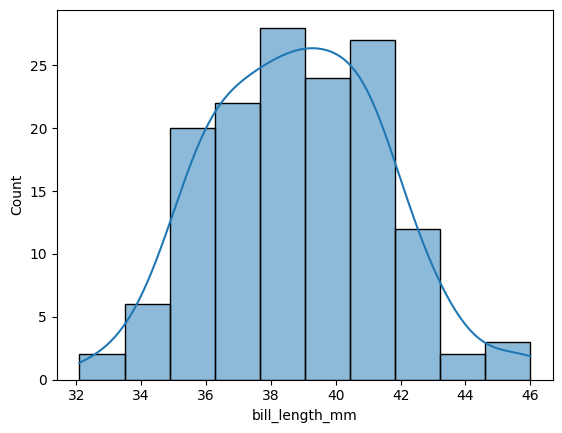

Średnia: 38.82
Mediana: 38.85
Skośność: 0.15616184771639763
Kurtoza: -0.18127977896608938


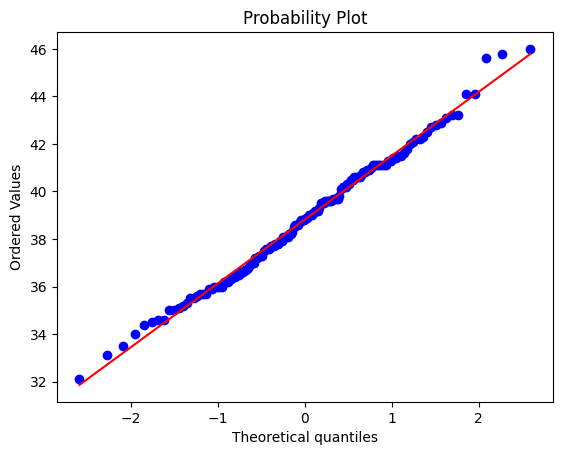

Statystyka W: 0.992888894142337
Wartość p: 0.6848410055512179

Chinstrap


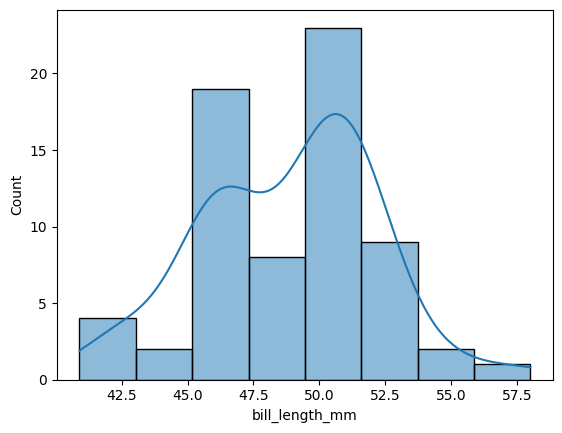

Średnia: 48.83
Mediana: 49.55
Skośność: -0.08856426997678174
Kurtoza: -0.05367915496168729


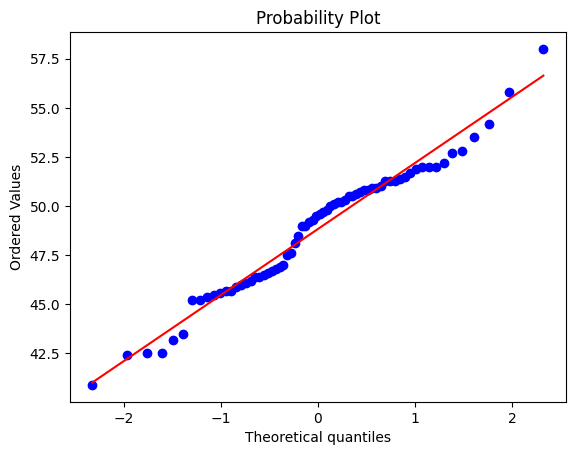

Statystyka W: 0.9752496075500775
Wartość p: 0.1940925740620773
Odrzucono normalność na poziomie istotności: 5.0%


In [3]:
import seaborn as sns
from scipy import stats

print("penguins.describe()")
display(penguins.describe())  # Zestawienie wartości kolumn danych numerycznych


# Adelie
print("Adelie")
adelie = penguins[penguins["species"] == "Adelie"]
adelie_bill_length = adelie["bill_length_mm"]

sns.histplot(data=adelie_bill_length, kde=True, stat="count")
plt.show()

print(f"Średnia: {round(adelie_bill_length.mean(), 2)}")
print(f"Mediana: {round(adelie_bill_length.median(), 2)}")

print(f"Skośność: {stats.skew(adelie_bill_length)}")
print(f"Kurtoza: {stats.kurtosis(adelie_bill_length)}")

stats.probplot(adelie_bill_length, dist="norm", plot=plt)
plt.show()

adelie_statistic, adelie_p_value = stats.shapiro(adelie_bill_length)
print(f"Statystyka W: {adelie_statistic}")
print(f"Wartość p: {adelie_p_value}")

adelie_anderson_result = stats.anderson(adelie_bill_length, dist="norm")
for i in reversed(range(len(adelie_anderson_result.critical_values))):
    if adelie_anderson_result.statistic > adelie_anderson_result.critical_values[i]:
        print(
            f"Odrzucono normalność na poziomie istotności: {adelie_anderson_result.significance_level[i]}%"
        )
        break


# Chinstrap
print("\nChinstrap")
chinstrap = penguins[penguins["species"] == "Chinstrap"]
chinstrap_bill_length = chinstrap["bill_length_mm"]

sns.histplot(data=chinstrap_bill_length, kde=True, stat="count")
plt.show()

print(f"Średnia: {round(chinstrap_bill_length.mean(), 2)}")
print(f"Mediana: {round(chinstrap_bill_length.median(), 2)}")

print(f"Skośność: {stats.skew(chinstrap_bill_length)}")
print(f"Kurtoza: {stats.kurtosis(chinstrap_bill_length)}")

stats.probplot(chinstrap_bill_length, dist="norm", plot=plt)
plt.show()

chinstrap_statistic, chinstrap_p_value = stats.shapiro(chinstrap_bill_length)
print(f"Statystyka W: {chinstrap_statistic}")
print(f"Wartość p: {chinstrap_p_value}")

chinstrap_anderson_result = stats.anderson(chinstrap_bill_length, dist="norm")
for i in reversed(range(len(chinstrap_anderson_result.critical_values))):
    if (
        chinstrap_anderson_result.statistic
        > chinstrap_anderson_result.critical_values[i]
    ):
        print(
            f"Odrzucono normalność na poziomie istotności: {chinstrap_anderson_result.significance_level[i]}%"
        )
        break

## 1.3 Porównanie dystrybucji

Chinstrap
Średnia samców: 51.09
Mediana samców: 50.95
Średnia samic: 46.57
Mediana samic: 46.3


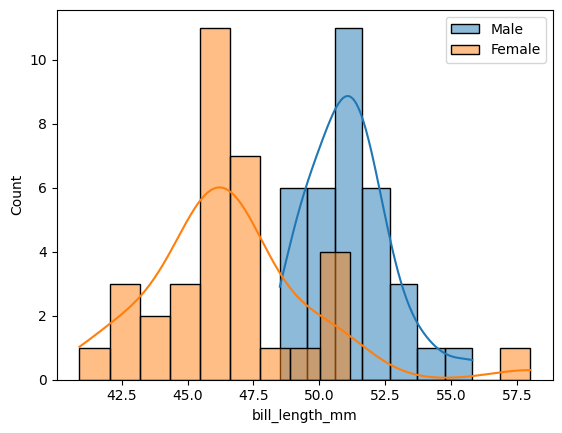

Statystyka t: 7.574124752810247
Wartość p: 8.918408581732456e-10

Adelie
Średnia samców: 40.39
Mediana samców: 40.6
Średnia samic: 37.26
Mediana samic: 37.0


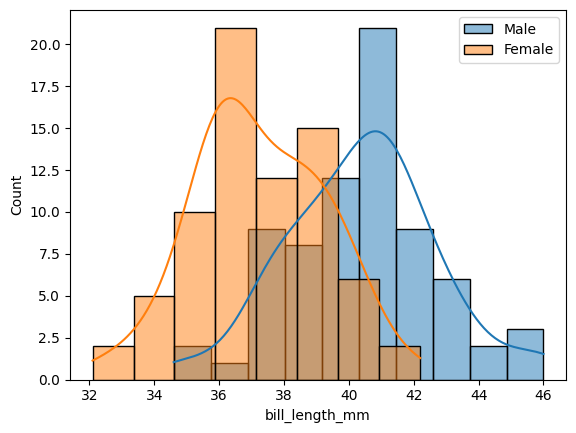

Statystyka t: 8.776549679516735
Wartość p: 4.801082384425442e-15

body_mass_g
Średnia Adelie: 3706.16
Mediana Adelie: 3700.0
Średnia Chinstrap: 3733.09
Mediana Chinstrap: 3700.0
Statystyka t: -0.44792967534690686
Wartość p: 0.6548333152810653


In [4]:
from scipy.stats import ttest_ind

# Chinstrap
print("Chinstrap")

chinstrap_male = chinstrap[chinstrap["sex"] == "Male"]
chinstrap_female = chinstrap[chinstrap["sex"] == "Female"]

chinstrap_male_bill_length = chinstrap_male["bill_length_mm"]
chinstrap_female_bill_length = chinstrap_female["bill_length_mm"]

print(f"Średnia samców: {round(chinstrap_male_bill_length.mean(), 2)}")
print(f"Mediana samców: {round(chinstrap_male_bill_length.median(), 2)}")

print(f"Średnia samic: {round(chinstrap_female_bill_length.mean(), 2)}")
print(f"Mediana samic: {round(chinstrap_female_bill_length.median(), 2)}")

sns.histplot(data=chinstrap_male_bill_length, kde=True, stat="count", label="Male")
sns.histplot(data=chinstrap_female_bill_length, kde=True, stat="count", label="Female")
plt.legend()
plt.show()

chinstrap_ttest_result = ttest_ind(
    chinstrap_male_bill_length,
    chinstrap_female_bill_length,
    equal_var=False,
)
print("Statystyka t:", chinstrap_ttest_result.statistic)
print("Wartość p:", chinstrap_ttest_result.pvalue)


# Adelie
print("\nAdelie")

adelie_male = adelie[adelie["sex"] == "Male"]
adelie_female = adelie[adelie["sex"] == "Female"]

adelie_male_bill_length = adelie_male["bill_length_mm"]
adelie_female_bill_length = adelie_female["bill_length_mm"]

print(f"Średnia samców: {round(adelie_male_bill_length.mean(), 2)}")
print(f"Mediana samców: {round(adelie_male_bill_length.median(), 2)}")

print(f"Średnia samic: {round(adelie_female_bill_length.mean(), 2)}")
print(f"Mediana samic: {round(adelie_female_bill_length.median(), 2)}")

sns.histplot(data=adelie_male_bill_length, kde=True, stat="count", label="Male")
sns.histplot(data=adelie_female_bill_length, kde=True, stat="count", label="Female")
plt.legend()
plt.show()

adelie_ttest_result = ttest_ind(
    adelie_male_bill_length,
    adelie_female_bill_length,
    equal_var=False,
)
print("Statystyka t:", adelie_ttest_result.statistic)
print("Wartość p:", adelie_ttest_result.pvalue)


# body_mass_g
print("\nbody_mass_g")

adelie_body_mass = adelie["body_mass_g"]
chinstrap_body_mass = chinstrap["body_mass_g"]

print(f"Średnia Adelie: {round(adelie_body_mass.mean(), 2)}")
print(f"Mediana Adelie: {round(adelie_body_mass.median(), 2)}")

print(f"Średnia Chinstrap: {round(chinstrap_body_mass.mean(), 2)}")
print(f"Mediana Chinstrap: {round(chinstrap_body_mass.median(), 2)}")

body_mass_ttest_result = ttest_ind(
    adelie_body_mass,
    chinstrap_body_mass,
    equal_var=False,
)
print("Statystyka t:", body_mass_ttest_result.statistic)
print("Wartość p:", body_mass_ttest_result.pvalue)